# Model Analysis

Scatter plots of participant accuracy (x) vs expected accuracy of the BIC-winning model (y), split by condition and phase.


In [16]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [17]:
EXCLUDED_PARTICIPANTS = {107, 109}

def participant_group(pid):
    pid = int(pid)
    if 1 <= pid <= 60:
        return 'interleaved' if (pid % 2 == 1) else 'blocked'
    if 61 <= pid <= 90:
        return 'blocked2'
    if 91 <= pid <= 125:
        return 'blocked3'
    return 'other'

def resolve_model_fits_dir(base_dir=None):
    candidates = []
    if base_dir is not None:
        candidates.append(Path(base_dir))
    candidates.extend([Path('model_fits'), Path('../model_fits')])
    for c in candidates:
        if c.exists():
            return c
    raise FileNotFoundError('Could not find model_fits directory (tried model_fits and ../model_fits).')

def load_best_seed_summary(base_dir=None):
    base = resolve_model_fits_dir(base_dir)
    summary_path = base / 'best_seed_summary.csv'
    if summary_path.exists():
        return pd.read_csv(summary_path)
    return None

def resolve_result_path(model_name, participant_id, base_dir=None, best_seed_summary=None):
    base = resolve_model_fits_dir(base_dir)
    participant_id = int(participant_id)
    participant_dir = base / model_name / str(participant_id)
    legacy_path = participant_dir / 'results.json'
    if legacy_path.exists():
        return legacy_path

    summary = best_seed_summary if best_seed_summary is not None else load_best_seed_summary(base)
    if summary is not None and not summary.empty:
        subset = summary[(summary['model'] == model_name) & (summary['participant_id'].astype(int) == participant_id)]
        if not subset.empty:
            summary_path = Path(subset.iloc[0]['results_path'])
            if summary_path.exists():
                return summary_path

    seed_paths = sorted(participant_dir.glob('seed_*/results.json'))
    if not seed_paths:
        raise FileNotFoundError(f'No results found for model={model_name}, participant={participant_id}')

    best_path = None
    best_loglik = -np.inf
    for path in seed_paths:
        with open(path, 'r', encoding='utf-8') as f:
            res = json.load(f)
        loglik = res.get('metrics', {}).get('loglik', -np.inf)
        if loglik > best_loglik:
            best_loglik = loglik
            best_path = path
    if best_path is None:
        raise FileNotFoundError(f'No usable seeded results found for model={model_name}, participant={participant_id}')
    return best_path

def load_result(base_dir, model_name, participant_id, best_seed_summary=None):
    p = resolve_result_path(model_name, participant_id, base_dir=base_dir, best_seed_summary=best_seed_summary)
    with open(p, 'r', encoding='utf-8') as f:
        return json.load(f)

def load_model_metrics(base_dir=None):
    base = resolve_model_fits_dir(base_dir)
    best_seed_summary = load_best_seed_summary(base)
    rows = []
    for model_dir in sorted([d for d in base.iterdir() if d.is_dir()]):
        model_name = model_dir.name
        participant_dirs = [d for d in model_dir.iterdir() if d.is_dir() and d.name.isdigit()]
        for pid_dir in sorted(participant_dirs, key=lambda x: int(x.name)):
            res = load_result(base, model_name, int(pid_dir.name), best_seed_summary=best_seed_summary)
            pid = int(res.get('participant_id', pid_dir.name))
            if pid in EXCLUDED_PARTICIPANTS:
                continue
            m = res.get('metrics', {})
            rows.append({
                'participant_id': pid,
                'group': participant_group(pid),
                'model': model_name,
                'BIC': m.get('BIC', np.nan),
                'AIC': m.get('AIC', np.nan),
                'seed': res.get('seed', np.nan),
            })
    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError('No model metrics found.')
    return df

def get_bic_winners(metrics_df):
    tmp = metrics_df.dropna(subset=['BIC']).copy()
    idx = tmp.groupby('participant_id')['BIC'].idxmin()
    return tmp.loc[idx, ['participant_id', 'group', 'model', 'BIC']].sort_values('participant_id').reset_index(drop=True)

def build_accuracy_table(winners_df, base_dir=None):
    base = resolve_model_fits_dir(base_dir)
    best_seed_summary = load_best_seed_summary(base)
    rows = []
    for _, w in winners_df.iterrows():
        res = load_result(base, w['model'], int(w['participant_id']), best_seed_summary=best_seed_summary)
        pa = res.get('participant_accuracy', {})
        ea = res.get('expected_accuracy', {})
        rows.append({
            'participant_id': int(w['participant_id']),
            'group': w['group'],
            'winning_model': w['model'],
            'participant_train': pa.get('training', np.nan),
            'participant_test': pa.get('test', np.nan),
            'expected_train': ea.get('training', np.nan),
            'expected_test': ea.get('test', np.nan),
            'winning_BIC': w['BIC'],
        })
    return pd.DataFrame(rows).sort_values('participant_id').reset_index(drop=True)


In [18]:
def plot_accuracy_scatter_by_condition(acc_df):
    groups = ['interleaved', 'blocked', 'blocked2', 'blocked3']
    titles = {
        'interleaved': 'Interleaved',
        'blocked': 'Blocked',
        'blocked2': 'Blocked2',
        'blocked3': 'Blocked3',
    }

    fig, axes = plt.subplots(4, 2, figsize=(12, 18), sharex=True, sharey=True)

    for r, g in enumerate(groups):
        sub = acc_df[acc_df['group'] == g].copy()

        # Training
        ax = axes[r, 0]
        x = sub['participant_train'].to_numpy(dtype=float)
        y = sub['expected_train'].to_numpy(dtype=float)
        m = np.isfinite(x) & np.isfinite(y)
        ax.scatter(x[m], y[m], alpha=0.8, s=30)
        ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
        ax.set_title(f"{titles[g]} - Training (n={int(m.sum())})")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel('Participant accuracy')
        ax.set_ylabel('Winning-model expected accuracy')

        # Test
        ax = axes[r, 1]
        x = sub['participant_test'].to_numpy(dtype=float)
        y = sub['expected_test'].to_numpy(dtype=float)
        m = np.isfinite(x) & np.isfinite(y)
        ax.scatter(x[m], y[m], alpha=0.8, s=30, color='#d62728')
        ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
        ax.set_title(f"{titles[g]} - Test (n={int(m.sum())})")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel('Participant accuracy')
        ax.set_ylabel('Winning-model expected accuracy')

    fig.suptitle('Participant vs BIC-winning-model expected accuracy', y=1.0)
    plt.tight_layout()
    plt.show()


,participant_id,group,model,BIC
0,1,interleaved,gmm_no_forgetting_tied_lrs,291.833771
1,2,blocked,wm_last_m_category_specific,465.585343
2,3,interleaved,wm_exponential_decay,205.806523
3,4,blocked,wm_exponential_decay,363.560158
4,5,interleaved,wm_exponential_decay,562.186933


,participant_id,group,winning_model,participant_train,participant_test,expected_train,expected_test,winning_BIC
0,1,interleaved,gmm_no_forgetting_tied_lrs,0.842697,0.908730,0.829432,0.885839,291.833771
1,2,blocked,wm_last_m_category_specific,0.869318,0.636364,0.840602,0.544846,465.585343
2,3,interleaved,wm_exponential_decay,0.977778,0.900794,0.944663,0.766863,205.806523
3,4,blocked,wm_exponential_decay,0.915730,0.699187,0.904909,0.596638,363.560158
4,5,interleaved,wm_exponential_decay,0.644444,0.697211,0.721129,0.634339,562.186933


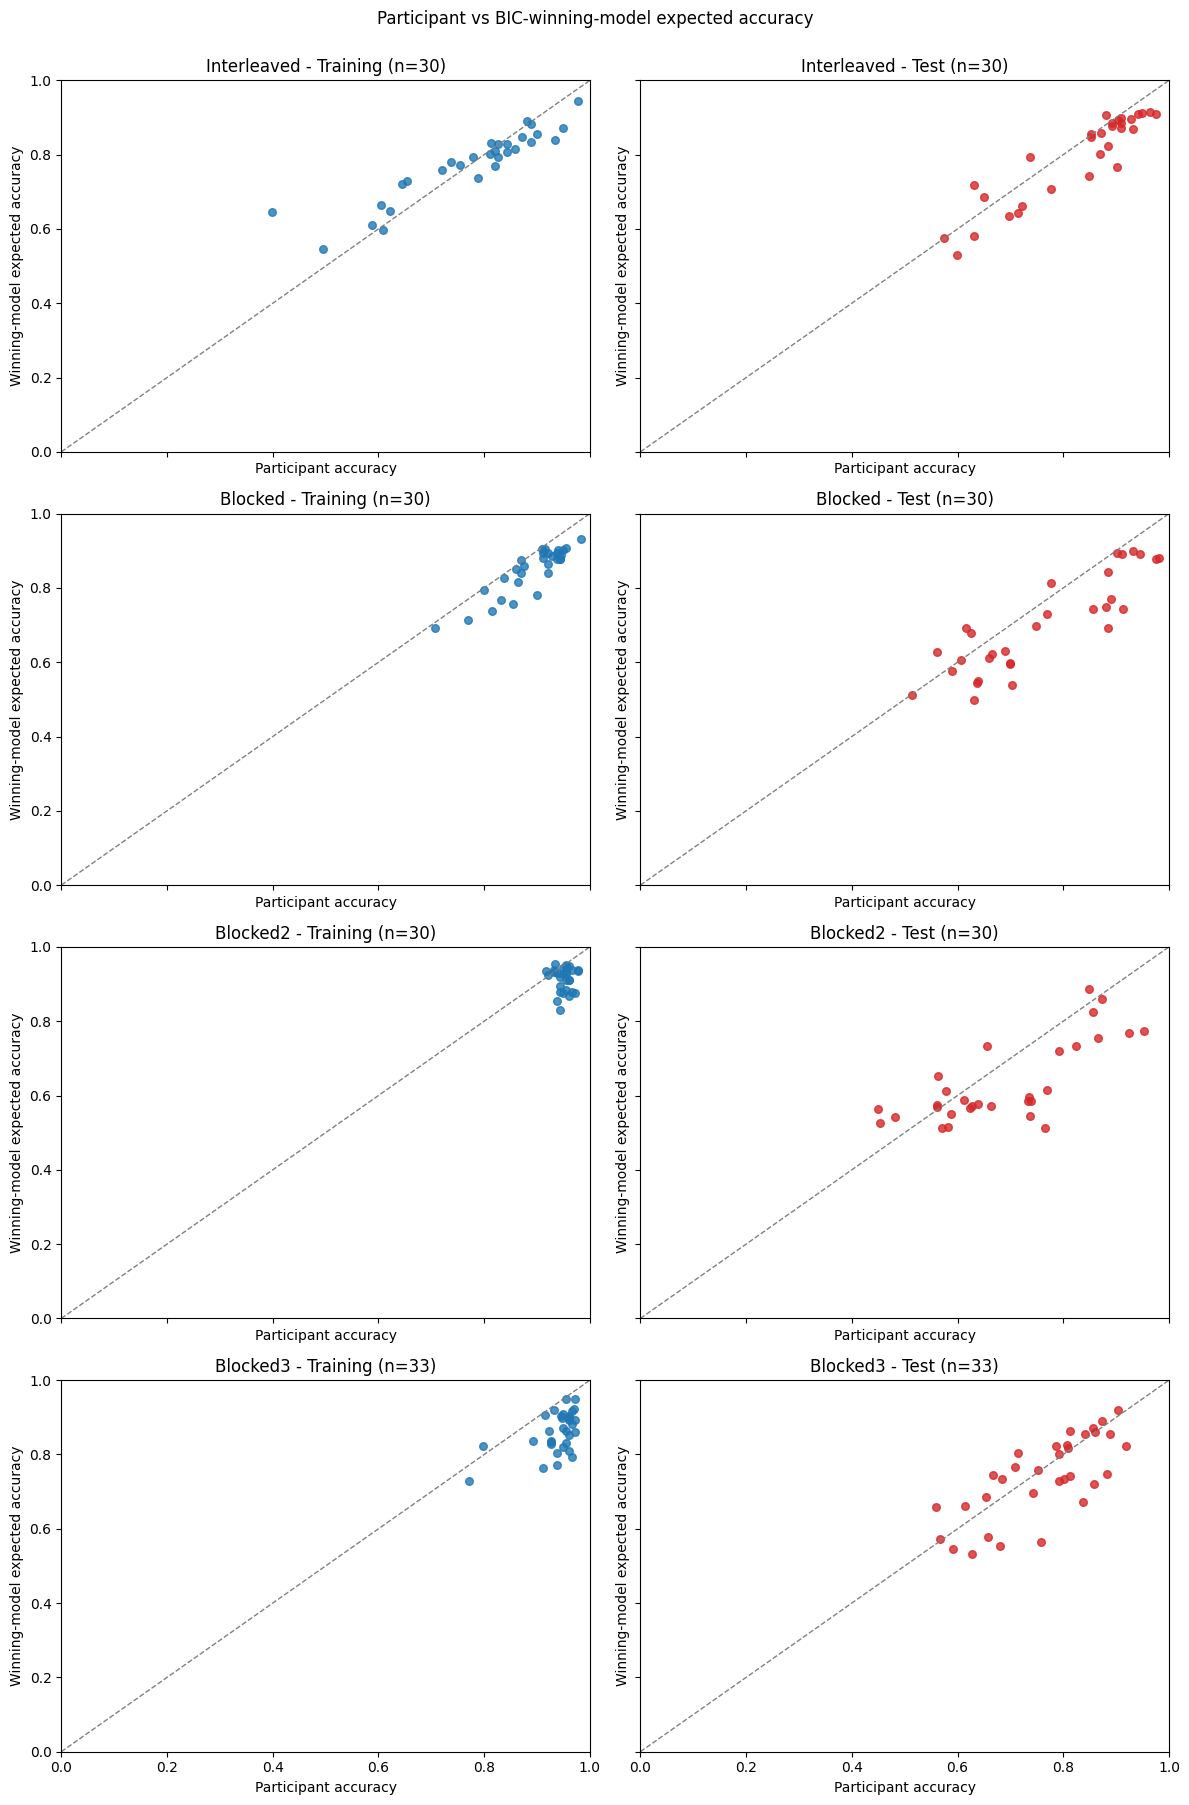

In [19]:
metrics_df = load_model_metrics('../model_fits')
winners_bic = get_bic_winners(metrics_df)
acc_df = build_accuracy_table(winners_bic, '../model_fits')

display(winners_bic.head())
display(acc_df.head())

plot_accuracy_scatter_by_condition(acc_df)


Files for sbj107 not found in ../Results.
Files for sbj109 not found in ../Results.


,participant_id,group,winning_model,participant_seen,participant_unseen,expected_seen,expected_unseen
0,1,interleaved,gmm_no_forgetting_tied_lrs,0.936508,0.880952,0.934742,0.836935
1,2,blocked,wm_last_m_category_specific,0.658537,0.613445,0.564951,0.524064
2,3,interleaved,wm_exponential_decay,0.984127,0.817460,0.993574,0.540151
3,4,blocked,wm_exponential_decay,0.709677,0.688525,0.657036,0.535251
4,5,interleaved,wm_exponential_decay,0.753968,0.640000,0.753108,0.514620


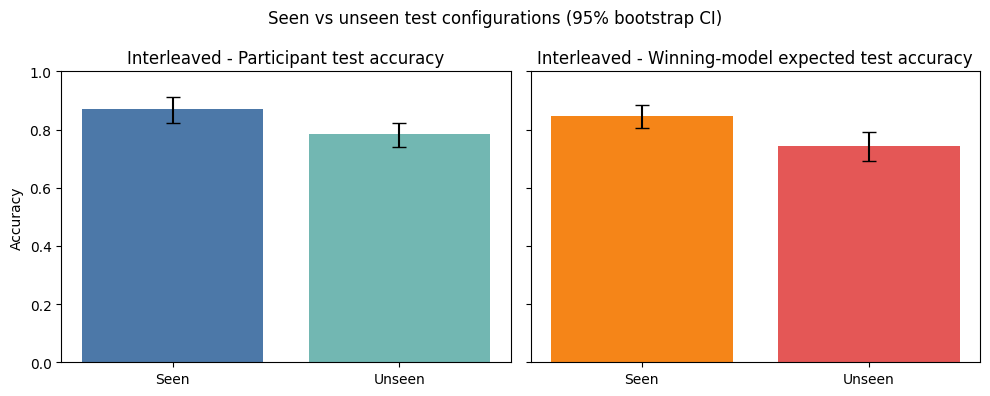

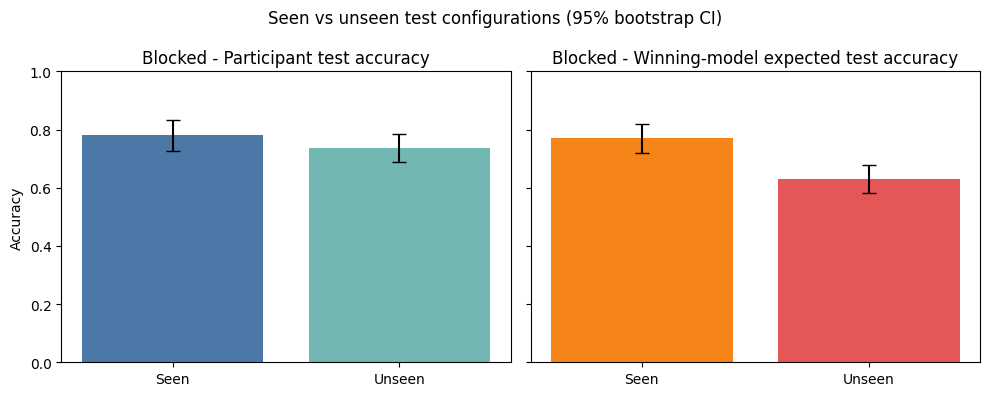

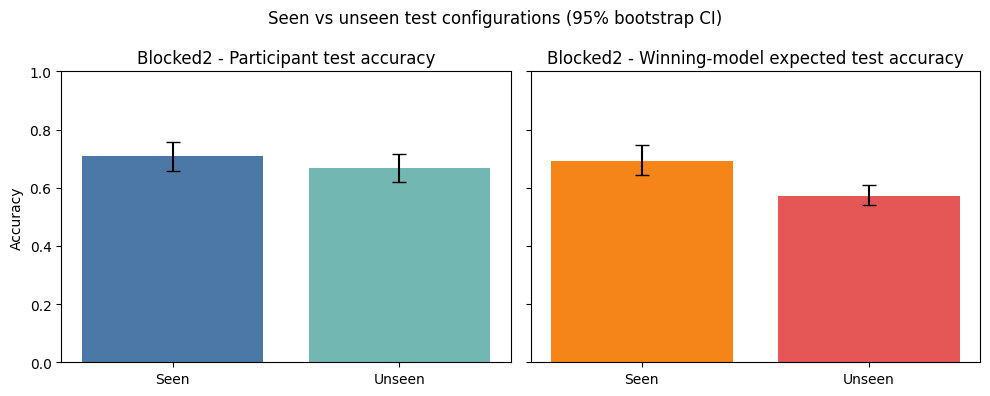

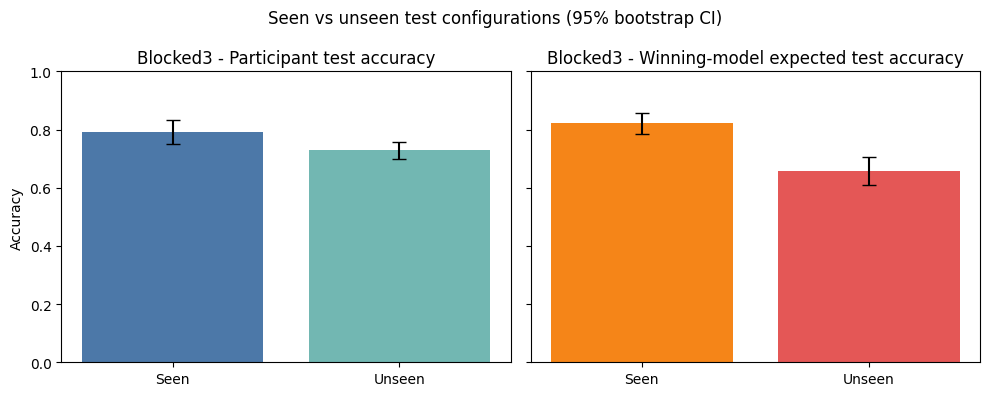

In [20]:
# Test accuracy on seen vs unseen configurations (winning model by BIC)
# Re-runs winning model per participant to get trial-level expected test accuracy.
import os, sys
sys.path.append(os.path.abspath('../agents'))
sys.path.append(os.path.abspath('../utils'))

from get_data import read_mat_files
from GMM_nuts import HardLabelTwoMixtureFullCov
from WM import LastMInverseDistanceModel, ExponentialDecayInverseDistanceModel

def stim_key(x):
    a = np.asarray(x).astype(int).tolist()
    return (int(a[0]), int(a[1]))

def seen_mask_from_training(data):
    tr_stim = np.asarray(data['training']['stimuli'])
    te_stim = np.asarray(data['test']['stimuli'])
    seen = {stim_key(s) for s in tr_stim}
    return np.array([stim_key(s) in seen for s in te_stim], dtype=bool)

def participant_test_acc_split(data, seen_mask):
    y = np.asarray(data['test']['labels']).astype(int)
    a = np.asarray(data['test']['action']).astype(int)
    lost = np.asarray(data['test']['trialLost']).astype(int)
    keep = (lost == 0)

    m_seen = keep & seen_mask
    m_unseen = keep & (~seen_mask)

    acc_seen = float(np.mean(a[m_seen] == y[m_seen])) if np.any(m_seen) else np.nan
    acc_unseen = float(np.mean(a[m_unseen] == y[m_unseen])) if np.any(m_unseen) else np.nan
    return acc_seen, acc_unseen

def model_expected_test_acc_split(model_name, res, data, seen_mask):
    theta = res.get('theta_hat', {})
    y = np.asarray(data['test']['labels']).astype(float)
    lost = np.asarray(data['test']['trialLost']).astype(int)
    keep = (lost == 0)

    if model_name.startswith('gmm_'):
        model = HardLabelTwoMixtureFullCov(res.get('config', {}))
        trace = model.trace_sufficient_stats(
            alpha=theta['alpha'],
            lapse_rate=theta['lapse_rate'],
            data=data,
            eta_mu=theta.get('eta_mu'),
            eta_cov=theta.get('eta_cov'),
            rho=theta.get('rho'),
            mu_init=theta.get('mu_init'),
            sigma_init=theta.get('sigma_init'),
        )
        exp_test = np.asarray(trace['test']['expected_acc'], dtype=float)

    elif model_name == 'wm_last_m':
        model = LastMInverseDistanceModel(M=12)
        pred = model.predict(
            data=data,
            lapse_rate=theta['lapse_rate'],
            M=theta.get('M'),
            use_category_specific_memory=False,
        )
        p1_test = np.asarray(pred['p1_test'], dtype=float)
        exp_test = y * p1_test + (1.0 - y) * (1.0 - p1_test)

    elif model_name == 'wm_last_m_category_specific':
        model = LastMInverseDistanceModel(use_category_specific_memory=True, M0=12, M1=12)
        pred = model.predict(
            data=data,
            lapse_rate=theta['lapse_rate'],
            use_category_specific_memory=True,
            M0=theta.get('M0'),
            M1=theta.get('M1'),
        )
        p1_test = np.asarray(pred['p1_test'], dtype=float)
        exp_test = y * p1_test + (1.0 - y) * (1.0 - p1_test)

    elif model_name == 'wm_exponential_decay':
        model = ExponentialDecayInverseDistanceModel(decay_rate=0.1)
        pred = model.predict(
            data=data,
            lapse_rate=theta['lapse_rate'],
            decay_rate=theta.get('decay_rate'),
            use_dual_decay=False,
        )
        p1_test = np.asarray(pred['p1_test'], dtype=float)
        exp_test = y * p1_test + (1.0 - y) * (1.0 - p1_test)

    elif model_name == 'wm_exponential_decay_dual':
        model = ExponentialDecayInverseDistanceModel(use_dual_decay=True, decay_time=0.1, decay_count=0.1)
        pred = model.predict(
            data=data,
            lapse_rate=theta['lapse_rate'],
            use_dual_decay=True,
            decay_time=theta.get('decay_time'),
            decay_count=theta.get('decay_count'),
        )
        p1_test = np.asarray(pred['p1_test'], dtype=float)
        exp_test = y * p1_test + (1.0 - y) * (1.0 - p1_test)

    else:
        raise ValueError(f'Unsupported model for expected-accuracy split: {model_name}')

    m_seen = keep & seen_mask
    m_unseen = keep & (~seen_mask)

    e_seen = float(np.nanmean(exp_test[m_seen])) if np.any(m_seen) else np.nan
    e_unseen = float(np.nanmean(exp_test[m_unseen])) if np.any(m_unseen) else np.nan
    return e_seen, e_unseen

def bootstrap_mean_ci(x, n_boot=5000, alpha=0.05, rng=None):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan
    if rng is None:
        rng = np.random.default_rng(0)
    idx = rng.integers(0, x.size, size=(n_boot, x.size))
    means = x[idx].mean(axis=1)
    m = float(x.mean())
    lo = float(np.quantile(means, alpha / 2))
    hi = float(np.quantile(means, 1 - alpha / 2))
    return m, lo, hi

fits_base = resolve_model_fits_dir('../model_fits')
best_seed_summary = load_best_seed_summary(fits_base)
all_data = read_mat_files(base_dir='../Results')

rows = []
for _, w in winners_bic.iterrows():
    pid = int(w['participant_id'])
    model_name = w['model']
    if pid in EXCLUDED_PARTICIPANTS:
        continue
    if pid not in all_data:
        continue

    pdata = all_data[pid]
    seen_mask = seen_mask_from_training(pdata)

    try:
        res = load_result(fits_base, model_name, pid, best_seed_summary=best_seed_summary)
    except FileNotFoundError:
        continue

    p_seen, p_unseen = participant_test_acc_split(pdata, seen_mask)
    e_seen, e_unseen = model_expected_test_acc_split(model_name, res, pdata, seen_mask)

    rows.append({
        'participant_id': pid,
        'group': participant_group(pid),
        'winning_model': model_name,
        'participant_seen': p_seen,
        'participant_unseen': p_unseen,
        'expected_seen': e_seen,
        'expected_unseen': e_unseen,
    })

split_df = pd.DataFrame(rows).sort_values('participant_id').reset_index(drop=True)
display(split_df.head())

groups = ['interleaved', 'blocked', 'blocked2', 'blocked3']
group_titles = {
    'interleaved': 'Interleaved',
    'blocked': 'Blocked',
    'blocked2': 'Blocked2',
    'blocked3': 'Blocked3',
}
n_boot = 5000
rng = np.random.default_rng(2024)

for g in groups:
    sub = split_df[split_df['group'] == g].copy()

    ps_m, ps_lo, ps_hi = bootstrap_mean_ci(sub['participant_seen'], n_boot=n_boot, rng=rng)
    pu_m, pu_lo, pu_hi = bootstrap_mean_ci(sub['participant_unseen'], n_boot=n_boot, rng=rng)
    es_m, es_lo, es_hi = bootstrap_mean_ci(sub['expected_seen'], n_boot=n_boot, rng=rng)
    eu_m, eu_lo, eu_hi = bootstrap_mean_ci(sub['expected_unseen'], n_boot=n_boot, rng=rng)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    # Participant test accuracy
    means = [ps_m, pu_m]
    yerr = [[ps_m - ps_lo, pu_m - pu_lo], [ps_hi - ps_m, pu_hi - pu_m]]
    axes[0].bar(['Seen', 'Unseen'], means, yerr=yerr, capsize=5, color=['#4C78A8', '#72B7B2'])
    axes[0].set_title(f"{group_titles[g]} - Participant test accuracy")
    axes[0].set_ylabel('Accuracy')
    axes[0].set_ylim(0, 1)

    # Winning-model expected test accuracy
    means = [es_m, eu_m]
    yerr = [[es_m - es_lo, eu_m - eu_lo], [es_hi - es_m, eu_hi - eu_m]]
    axes[1].bar(['Seen', 'Unseen'], means, yerr=yerr, capsize=5, color=['#F58518', '#E45756'])
    axes[1].set_title(f"{group_titles[g]} - Winning-model expected test accuracy")
    axes[1].set_ylim(0, 1)

    fig.suptitle('Seen vs unseen test configurations (95% bootstrap CI)')
    plt.tight_layout()
    plt.show()


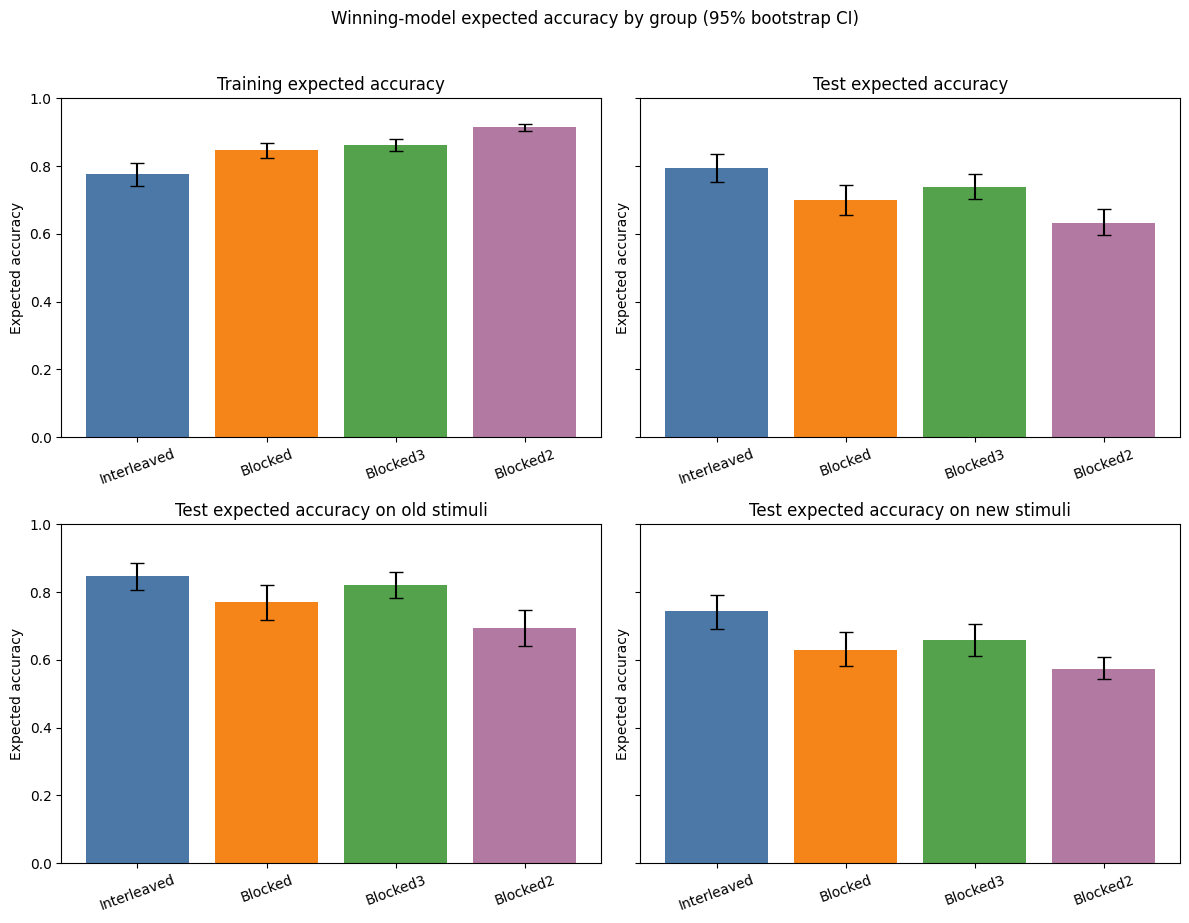

In [21]:
# Group-level expected-accuracy summaries (winning model by BIC)
# Order required: interleaved, blocked, blocked3, blocked2
group_order = ['interleaved', 'blocked', 'blocked3', 'blocked2']
group_labels = ['Interleaved', 'Blocked', 'Blocked3', 'Blocked2']

def bootstrap_mean_ci(x, n_boot=5000, alpha=0.05, rng=None):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan
    if rng is None:
        rng = np.random.default_rng(0)
    idx = rng.integers(0, x.size, size=(n_boot, x.size))
    means = x[idx].mean(axis=1)
    m = float(x.mean())
    lo = float(np.quantile(means, alpha / 2))
    hi = float(np.quantile(means, 1 - alpha / 2))
    return m, lo, hi

rng = np.random.default_rng(777)
n_boot = 5000

# Build per-participant metrics from existing tables
# acc_df columns: expected_train, expected_test
# split_df columns: expected_seen, expected_unseen
if 'acc_df' not in globals():
    raise RuntimeError('acc_df not found. Run previous cells that compute winners_bic/acc_df first.')
if 'split_df' not in globals():
    raise RuntimeError('split_df not found. Run the seen/unseen analysis cell first.')

summary_specs = [
    ('expected_train', 'Training expected accuracy'),
    ('expected_test', 'Test expected accuracy'),
    ('expected_seen', 'Test expected accuracy on old stimuli'),
    ('expected_unseen', 'Test expected accuracy on new stimuli'),
]

# Merge needed columns into one participant-level frame
base = acc_df[['participant_id', 'group', 'expected_train', 'expected_test']].copy()
extra = split_df[['participant_id', 'expected_seen', 'expected_unseen']].copy()
merged = base.merge(extra, on='participant_id', how='left')

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
axes = axes.ravel()

for ax, (col, title) in zip(axes, summary_specs):
    means = []
    yerr_lo = []
    yerr_hi = []

    for g in group_order:
        vals = merged.loc[merged['group'] == g, col].to_numpy(dtype=float)
        m, lo, hi = bootstrap_mean_ci(vals, n_boot=n_boot, rng=rng)
        means.append(m)
        yerr_lo.append(m - lo if np.isfinite(m) and np.isfinite(lo) else np.nan)
        yerr_hi.append(hi - m if np.isfinite(m) and np.isfinite(hi) else np.nan)

    ax.bar(group_labels, means, yerr=[yerr_lo, yerr_hi], capsize=5, color=['#4C78A8', '#F58518', '#54A24B', '#B279A2'])
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Expected accuracy')
    ax.tick_params(axis='x', rotation=20)

fig.suptitle('Winning-model expected accuracy by group (95% bootstrap CI)', y=1.02)
plt.tight_layout()
plt.show()


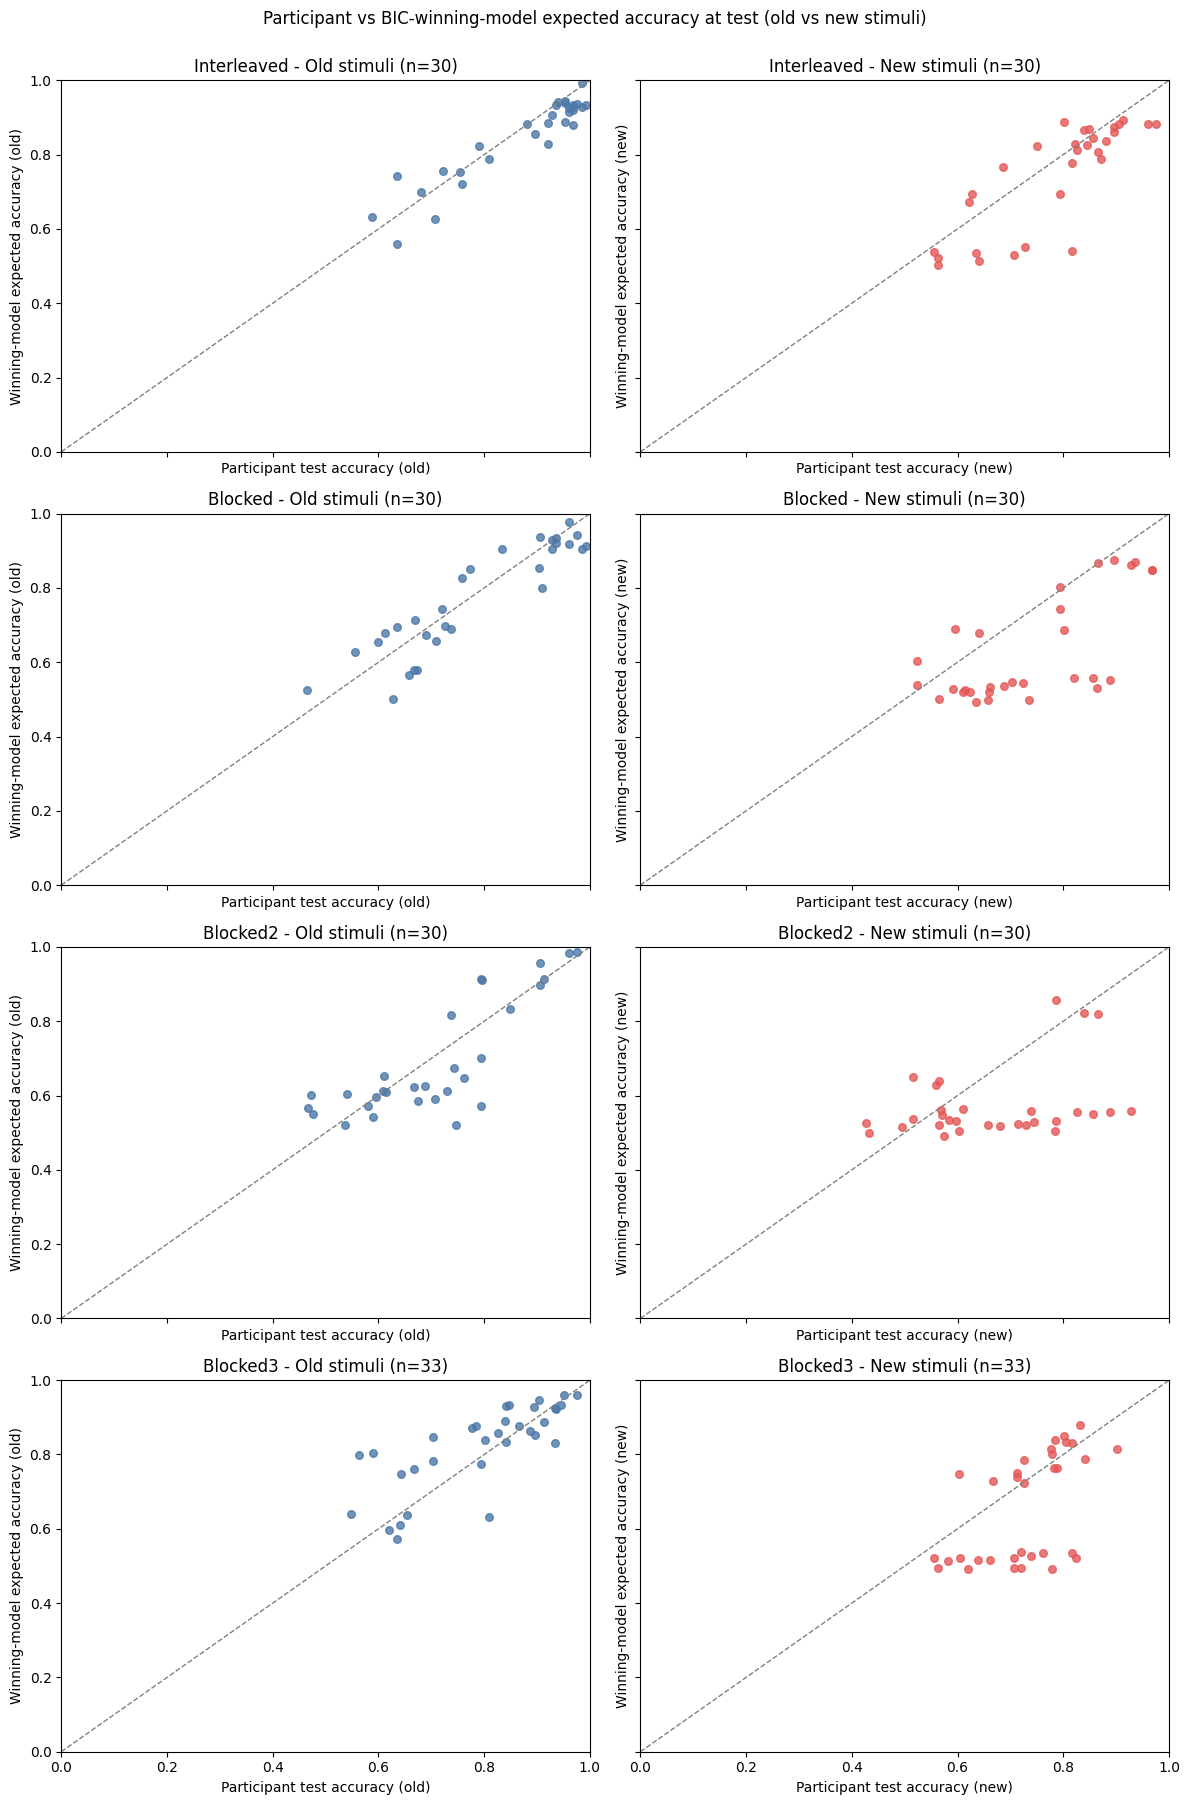

In [22]:
# Scatter plots at test time: old vs new stimuli, by condition
# x-axis: participant accuracy, y-axis: winning-model expected accuracy
if 'split_df' not in globals():
    raise RuntimeError('split_df not found. Run the seen/unseen analysis cell first.')

groups = ['interleaved', 'blocked', 'blocked2', 'blocked3']
group_titles = {
    'interleaved': 'Interleaved',
    'blocked': 'Blocked',
    'blocked2': 'Blocked2',
    'blocked3': 'Blocked3',
}

fig, axes = plt.subplots(4, 2, figsize=(12, 18), sharex=True, sharey=True)

for r, g in enumerate(groups):
    sub = split_df[split_df['group'] == g].copy()

    # Old stimuli
    ax = axes[r, 0]
    x = sub['participant_seen'].to_numpy(dtype=float)
    y = sub['expected_seen'].to_numpy(dtype=float)
    m = np.isfinite(x) & np.isfinite(y)
    ax.scatter(x[m], y[m], alpha=0.8, s=30, color='#4C78A8')
    ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
    ax.set_title(f"{group_titles[g]} - Old stimuli (n={int(m.sum())})")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Participant test accuracy (old)')
    ax.set_ylabel('Winning-model expected accuracy (old)')

    # New stimuli
    ax = axes[r, 1]
    x = sub['participant_unseen'].to_numpy(dtype=float)
    y = sub['expected_unseen'].to_numpy(dtype=float)
    m = np.isfinite(x) & np.isfinite(y)
    ax.scatter(x[m], y[m], alpha=0.8, s=30, color='#E45756')
    ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
    ax.set_title(f"{group_titles[g]} - New stimuli (n={int(m.sum())})")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Participant test accuracy (new)')
    ax.set_ylabel('Winning-model expected accuracy (new)')

fig.suptitle('Participant vs BIC-winning-model expected accuracy at test (old vs new stimuli)', y=1.0)
plt.tight_layout()
plt.show()
